In [1]:
from pathlib import Path

# Establish robust, relative project root paths (notebooks sit 1 level below project root)
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS = PROJECT_ROOT / "results"
FIG_DIR, MODEL_DIR, METRIC_DIR = RESULTS / "figures", RESULTS / "models", RESULTS / "metrics"

# Ensure results directories exist
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)


# K-Nearest Neighbors (KNN) Sentiment Classification
**Course**: IT2011 — Artificial Intelligence and Machine Learning  
**Project**: Binary Sentiment Classification on the IMDB Movie Review Dataset  
**Phase**: Model Training, Hyperparameter Tuning & Final Evaluation  

## 1. Setup, Imports, and Data Loading (Sparse CSR Format)

In [2]:
import os
import time
import json
import joblib
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Set aesthetic styling and reproducible seed
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Create output folders if they do not exist yet (never assume they exist)
FIGURES_DIR = FIG_DIR
MODELS_DIR = MODEL_DIR
METRICS_DIR = METRIC_DIR
DATA_DIR = DATA_PROCESSED

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# Load preprocessed feature matrices (Compressed Sparse Row - CSR) and labels
X_train_full = sparse.load_npz(os.path.join(DATA_DIR, "X_train_tfidf_main.npz"))
X_test = sparse.load_npz(os.path.join(DATA_DIR, "X_test_tfidf_main.npz"))
y_train_full = np.load(os.path.join(DATA_DIR, "y_train.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))

print(f"Full Train Matrix Shape : {X_train_full.shape} (CSR Sparse: {X_train_full.nnz:,} non-zero entries)")
print(f"Full Test Matrix Shape  : {X_test.shape}  (CSR Sparse: {X_test.nnz:,} non-zero entries)")
print(f"Train Positive Rate     : {y_train_full.mean():.4f} ({y_train_full.mean()*100:.2f}%)")
print(f"Test Positive Rate      : {y_test.mean():.4f} ({y_test.mean()*100:.2f}%)")


Full Train Matrix Shape : (39665, 5000) (CSR Sparse: 3,323,599 non-zero entries)
Full Test Matrix Shape  : (9917, 5000)  (CSR Sparse: 827,457 non-zero entries)
Train Positive Rate     : 0.5019 (50.19%)
Test Positive Rate      : 0.5019 (50.19%)


### Data Distribution Check: Class Balance After Deduplication
We inspect the class distribution across the training set, testing set, and combined dataset to confirm that class symmetry is maintained following duplicate removal and train/test splitting.


Figure saved to: C:\Users\user\Desktop\KNN\results\figures\class_balance_after_dedup.png
Train    - Negative: 19,758 (49.81%), Positive: 19,907 (50.19%)
Test     - Negative: 4,940 (49.81%), Positive: 4,977 (50.19%)
Combined - Negative: 24,698 (49.81%), Positive: 24,884 (50.19%)


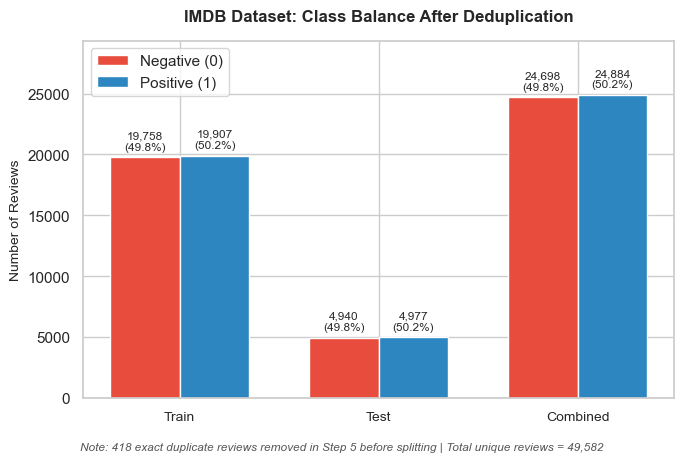

In [3]:
# Grouped bar chart of class distribution across Train, Test, and Combined splits
splits = ['Train', 'Test', 'Combined']
neg_counts = [(y_train_full == 0).sum(), (y_test == 0).sum(), (y_train_full == 0).sum() + (y_test == 0).sum()]
pos_counts = [(y_train_full == 1).sum(), (y_test == 1).sum(), (y_train_full == 1).sum() + (y_test == 1).sum()]
totals = [len(y_train_full), len(y_test), len(y_train_full) + len(y_test)]

x = np.arange(len(splits))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
bars_neg = ax.bar(x - width/2, neg_counts, width, label='Negative (0)', color='#E74C3C')
bars_pos = ax.bar(x + width/2, pos_counts, width, label='Positive (1)', color='#2E86C1')

ax.set_title("IMDB Dataset: Class Balance After Deduplication", fontsize=12, fontweight='bold', pad=14)
ax.set_ylabel("Number of Reviews", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(splits, fontsize=10)
ax.set_ylim(0, max(neg_counts + pos_counts) * 1.18)
ax.legend(frameon=True, facecolor='white')

# Annotate each bar with exact count and percentage
for bar, total in zip(bars_neg, totals):
    h = bar.get_height()
    pct = (h / total) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)

for bar, total in zip(bars_pos, totals):
    h = bar.get_height()
    pct = (h / total) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)

# Subtitle note regarding deduplication and total count
plt.figtext(0.5, -0.02, "Note: 418 exact duplicate reviews removed in Step 5 before splitting | Total unique reviews = 49,582",
            wrap=True, horizontalalignment='center', fontsize=8.5, fontstyle='italic', color='#555555')

plt.tight_layout()
fig_a1_path = os.path.join(FIGURES_DIR, "class_balance_after_dedup.png")
plt.savefig(fig_a1_path, dpi=150, bbox_inches='tight')

print(f"Figure saved to: {fig_a1_path}")
print(f"Train    - Negative: {neg_counts[0]:,} ({neg_counts[0]/totals[0]*100:.2f}%), Positive: {pos_counts[0]:,} ({pos_counts[0]/totals[0]*100:.2f}%)")
print(f"Test     - Negative: {neg_counts[1]:,} ({neg_counts[1]/totals[1]*100:.2f}%), Positive: {pos_counts[1]:,} ({pos_counts[1]/totals[1]*100:.2f}%)")
print(f"Combined - Negative: {neg_counts[2]:,} ({neg_counts[2]/totals[2]*100:.2f}%), Positive: {pos_counts[2]:,} ({pos_counts[2]/totals[2]*100:.2f}%)")


### Interpretation of Class Balance
As visualized above, the classes are almost perfectly balanced (~50.19% Positive vs. ~49.81% Negative) across all three views. This proves that:
1. **Accuracy is a fair and meaningful evaluation metric**: Because neither class dominates, high accuracy cannot be trivially gamed by predicting only the majority class.
2. **The majority baseline is ~50.19%**: Any acceptable machine learning model must substantially outperform random chance (~50%).
3. **Stratification was successful**: `train_test_split(..., stratify=y)` preserved the identical positive/negative ratio across the training and testing partitions.


## 2. Majority-Class Benchmark (Zero-Rule Baseline)
The majority-class baseline represents the accuracy achieved by predicting the most frequent class for all instances without using any features. Any viable machine learning model must substantially exceed this benchmark.


In [4]:
# Calculate majority class proportion in the training set
train_pos_rate = y_train_full.mean()
baseline_acc = max(train_pos_rate, 1.0 - train_pos_rate)

print("=" * 60)
print(f"MAJORITY-CLASS DUMMY BASELINE ACCURACY: {baseline_acc * 100:.2f}%")
print("Any valid machine learning model must substantially exceed this reference score.")
print("=" * 60)


MAJORITY-CLASS DUMMY BASELINE ACCURACY: 50.19%
Any valid machine learning model must substantially exceed this reference score.


## 3. Tuning Subsample Creation (Train)

In [5]:
from sklearn.model_selection import train_test_split

# Sample 8,000 instances strictly from the training dataset
X_tune, _, y_tune, _ = train_test_split(
    X_train_full, y_train_full,
    train_size=8000,
    stratify=y_train_full,
    random_state=RANDOM_STATE
)

print(f"Tuning Subsample Shape : {X_tune.shape}")
print(f"Tuning Positive Rate   : {y_tune.mean():.4f} ({y_tune.mean()*100:.2f}%)")
print(f"Positive Samples: {(y_tune == 1).sum():,} | Negative Samples: {(y_tune == 0).sum():,}")


Tuning Subsample Shape : (8000, 5000)
Tuning Positive Rate   : 0.5019 (50.19%)
Positive Samples: 4,015 | Negative Samples: 3,985


## 4. Compare Feature Representations
during the preprocessing stage, we created 6 distinct representation matrices:
1. `bow_2500`: Raw Bag-of-Words (2,500 unigrams)
2. `tfidf_2500`: Standard TF-IDF (2,500 unigrams)
3. `tfidf_5000_linear`: Standard TF-IDF (5,000 unigrams + bigrams, linear TF)
4. `tfidf_main`: Main TF-IDF (5,000 unigrams + bigrams, sublinear logarithmic TF scaling)
5. `tfidf_stemmed`: TF-IDF (5,000 unigrams + bigrams, Snowball stemming applied)
6. `tfidf_default_stop`: TF-IDF with generic unedited stopwords (loss of negations like *"not"*, *"never"*)

Here, we evaluate all 6 representations on our subsample using a stratified 80/20 train/validation split (6,400 sub-train, 1,600 validation) with fixed KNN ($K=15$, `metric='cosine'`, `algorithm='brute'`).


In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

# Stratified 80/20 partition of the tuning subsample
sub_idx, val_idx = train_test_split(
    np.arange(len(y_tune)),
    test_size=0.20,
    stratify=y_tune,
    random_state=RANDOM_STATE
)

y_subtrain = y_tune[sub_idx]
y_val = y_tune[val_idx]

# List the 6 representation matrices saved in Step 5
repr_files = [
    ("BoW (2500 Unigrams)", "X_train_bow_2500.npz"),
    ("TF-IDF (2500 Unigrams)", "X_train_tfidf_2500.npz"),
    ("TF-IDF (5000 Linear TF)", "X_train_tfidf_5000_linear.npz"),
    ("TF-IDF Main (5000 Sublinear)", "X_train_tfidf_main.npz"),
    ("TF-IDF Stemmed", "X_train_tfidf_stemmed.npz"),
    ("TF-IDF Default Stopwords", "X_train_tfidf_default_stop.npz"),
]

# Train fixed KNN (K=15, Cosine distance, brute-force) across each representation
repr_benchmark = []
for name, fname in repr_files:
    X_full = sparse.load_npz(os.path.join(DATA_DIR, fname))
    X_tune_repr, _, _, _ = train_test_split(
        X_full, y_train_full, train_size=8000, stratify=y_train_full, random_state=RANDOM_STATE
    )
    
    t0 = time.perf_counter()
    knn_repr = KNeighborsClassifier(n_neighbors=15, metric="cosine", algorithm="brute")
    knn_repr.fit(X_tune_repr[sub_idx], y_subtrain)
    y_pred_repr = knn_repr.predict(X_tune_repr[val_idx])
    elapsed = time.perf_counter() - t0
    
    repr_benchmark.append({
        "Representation": name,
        "Validation Accuracy": round(accuracy_score(y_val, y_pred_repr) * 100, 2),
        "F1-Score": round(f1_score(y_val, y_pred_repr), 4),
        "Runtime (s)": round(elapsed, 2)
    })

df_repr = pd.DataFrame(repr_benchmark)
print(df_repr.to_string(index=False))


              Representation  Validation Accuracy  F1-Score  Runtime (s)
         BoW (2500 Unigrams)                71.69    0.7057         0.29
      TF-IDF (2500 Unigrams)                76.31    0.7729         0.27
     TF-IDF (5000 Linear TF)                76.12    0.7693         0.25
TF-IDF Main (5000 Sublinear)                79.44    0.8014         0.27
              TF-IDF Stemmed                81.31    0.8193         0.27
    TF-IDF Default Stopwords                79.94    0.8063         0.27


### Visual Comparison of Feature Representations

We plot the validation accuracy and inference runtime across all 6 representations side-by-side to visually contrast their performance.


Figure saved to: C:\Users\user\Desktop\KNN\results\figures\representation_comparison.png


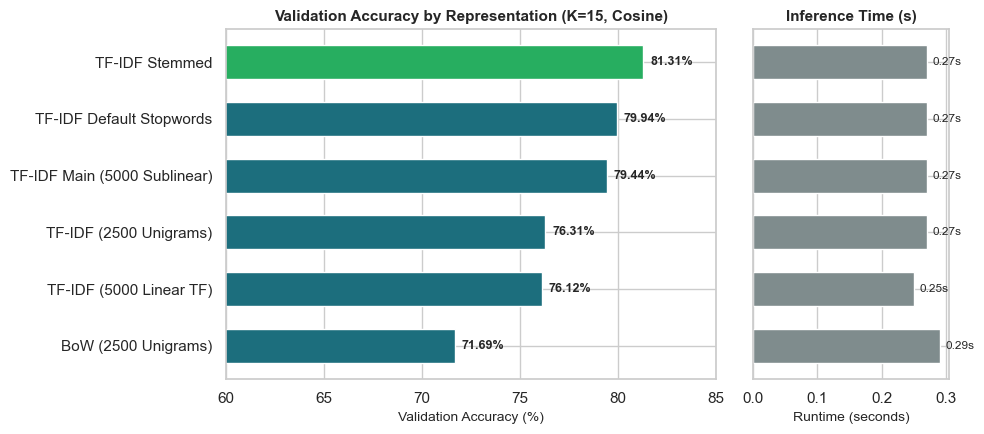

In [7]:
# Sort representations by accuracy from best to worst
df_sorted = df_repr.sort_values("Validation Accuracy", ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), gridspec_kw={'width_ratios': [2.5, 1]})

# Colors: best bar in green (#27AE60), others in teal (#1C6E7D)
best_rep = df_sorted.iloc[-1]["Representation"]
bar_colors = ['#27AE60' if r == best_rep else '#1C6E7D' for r in df_sorted["Representation"]]

# Subplot 1: Validation Accuracy (truncated x-axis from 60% for visibility)
bars = ax1.barh(df_sorted["Representation"], df_sorted["Validation Accuracy"], color=bar_colors, height=0.6)
ax1.set_xlim(60, 85)
ax1.set_xlabel("Validation Accuracy (%)", fontsize=10)
ax1.set_title("Validation Accuracy by Representation (K=15, Cosine)", fontsize=11, fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax1.annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height()/2),
                 xytext=(5, 0), textcoords="offset points", va='center', fontsize=9, fontweight='bold')

# Subplot 2: Inference Runtime
ax2.barh(df_sorted["Representation"], df_sorted["Runtime (s)"], color='#7F8C8D', height=0.6)
ax2.set_xlabel("Runtime (seconds)", fontsize=10)
ax2.set_title("Inference Time (s)", fontsize=11, fontweight='bold')
ax2.set_yticklabels([])  # Hide shared y-labels

for bar in ax2.patches:
    w = bar.get_width()
    ax2.annotate(f"{w:.2f}s", xy=(w, bar.get_y() + bar.get_height()/2),
                 xytext=(4, 0), textcoords="offset points", va='center', fontsize=8.5)

plt.tight_layout()
fig_a2_path = os.path.join(FIGURES_DIR, "representation_comparison.png")
plt.savefig(fig_a2_path, dpi=150)
print(f"Figure saved to: {fig_a2_path}")


### Interpretation of Representation Comparison
1. **Notice the Truncated Axis**: The horizontal accuracy axis begins at 60% rather than 0% specifically to make the differences visible across representations.
2. **Key Findings (Real Table Values)**:
   - **Bag-of-Words (2500)** scores lowest at **71.69%** on this single validation split, confirming that raw frequency counts distort KNN geometric distance.
   - TF-IDF variants significantly outperform BoW by normalizing vector lengths and downweighting common non-sentiment terms.
   - On this single 1,600-row validation partition, **TF-IDF Stemmed** scored highest (**81.31%**), followed by **TF-IDF Default Stopwords** (**79.94%**) and **TF-IDF Main** (**79.44%**).
   - However, because the validation set is only 1,600 reviews, differences of ~1–2 percentage points can reflect single-split partition noise. We perform a full 5-fold cross-validation check below to evaluate stability.


### Representation Robustness Check: 5-Fold Cross-Validation on Subsample

To ensure that the single 80/20 split was not skewed by random partition noise, we re-evaluate all 6 representations across 5 folds on the entire 8,000-sample tuning partition.


In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Configure 5-fold stratified cross-validation on the 8,000-sample tuning partition
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
knn_cv = KNeighborsClassifier(n_neighbors=15, metric="cosine", algorithm="brute", n_jobs=-1)

cv_repr_results = []
for name, fname in repr_files:
    X_full = sparse.load_npz(os.path.join(DATA_DIR, fname))
    X_tune_repr, _, _, _ = train_test_split(
        X_full, y_train_full, train_size=8000, stratify=y_train_full, random_state=RANDOM_STATE
    )
    
    scores = cross_val_score(knn_cv, X_tune_repr, y_tune, cv=cv5, scoring="accuracy")
    cv_repr_results.append({
        "Representation": name,
        "Mean CV Accuracy (%)": round(scores.mean() * 100, 2),
        "Std Dev (%)": round(scores.std() * 100, 2),
    })

df_cv_repr = pd.DataFrame(cv_repr_results)
print(df_cv_repr.to_string(index=False))


              Representation  Mean CV Accuracy (%)  Std Dev (%)
         BoW (2500 Unigrams)                 72.19         0.50
      TF-IDF (2500 Unigrams)                 75.65         1.04
     TF-IDF (5000 Linear TF)                 75.88         1.23
TF-IDF Main (5000 Sublinear)                 79.55         0.42
              TF-IDF Stemmed                 80.06         0.81
    TF-IDF Default Stopwords                 79.01         0.44


## 5. Tune with GridSearchCV
We tune the key KNN hyperparameters on the 8,000-sample tuning set using `StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)`.
To ensure the optimal $K$ does not sit at the edge of the grid, we extend $K$ up to $501$:
- `n_neighbors`: candidate values $[3, 5, 7, 11, 15, 21, 31, 51, 71, 101, 151, 201, 301, 501]$ (14 odd values).
- `weights`: `'uniform'` vs. `'distance'`.
- `metric`: `'cosine'` vs. `'euclidean'`.
- Total combinations: $14 \times 2 \times 2 = 56$ combinations $\times 3\text{ folds} = 168\text{ fits}$.


In [9]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 1. Configure 3-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# 2. Define the extended hyperparameter grid (14 K values x 2 weights x 2 metrics = 56 combinations x 3 folds = 168 fits)
grid = {
    "n_neighbors": [3, 5, 7, 11, 15, 21, 31, 51, 71, 101, 151, 201, 301, 501],
    "weights": ["uniform", "distance"],
    "metric": ["cosine", "euclidean"],
}

# 3. Instantiate GridSearchCV with brute-force KNN
knn_tune = KNeighborsClassifier(algorithm="brute")
search = GridSearchCV(
    estimator=knn_tune,
    param_grid=grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

# 4. Measure execution time
t0 = time.perf_counter()
search.fit(X_tune, y_tune)
cv_runtime = time.perf_counter() - t0

print(f"GridSearchCV completed in {cv_runtime:.2f} seconds ({len(grid['n_neighbors'])*len(grid['weights'])*len(grid['metric'])*3} total fits).")
print(f"Best Hyperparameters : {search.best_params_}")
print(f"Best Mean CV Accuracy: {search.best_score_ * 100:.2f}%\n")

# 5. Display CV accuracy table by K across combinations
cv_full = pd.DataFrame(search.cv_results_)
cv_pivot = cv_full.pivot_table(index='param_n_neighbors', columns=['param_metric', 'param_weights'], values='mean_test_score')
print("--- Mean CV Accuracy (%) by K and Configuration ---")
print((cv_pivot * 100).round(2).to_string())

# 6. Display Top-5 parameter combinations
cv_results_df = cv_full[
    ["param_n_neighbors", "param_weights", "param_metric", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score").head(5)

cv_results_df.columns = ["K", "Weights", "Metric", "Mean CV Accuracy", "Std Dev", "Rank"]
cv_results_df["Mean CV Accuracy"] = cv_results_df["Mean CV Accuracy"].apply(lambda x: f"{x*100:.2f}%")
cv_results_df["Std Dev"] = cv_results_df["Std Dev"].apply(lambda x: f"±{x*100:.2f}%")

print("\n--- Top 5 Hyperparameter Combinations ---")
print(cv_results_df.to_string(index=False))


GridSearchCV completed in 28.98 seconds (168 total fits).
Best Hyperparameters : {'metric': 'cosine', 'n_neighbors': 151, 'weights': 'uniform'}
Best Mean CV Accuracy: 84.36%

--- Mean CV Accuracy (%) by K and Configuration ---
param_metric        cosine         euclidean        
param_weights     distance uniform  distance uniform
param_n_neighbors                                   
3                    73.39   73.36     73.36   73.36
5                    75.29   75.26     75.26   75.26
7                    76.67   76.66     76.66   76.66
11                   78.00   78.00     78.00   78.00
15                   79.35   79.34     79.34   79.34
21                   80.24   80.22     80.22   80.22
31                   81.09   81.10     81.10   81.10
51                   82.24   82.22     82.22   82.22
71                   83.62   83.60     83.60   83.60
101                  83.65   83.64     83.64   83.64
151                  84.36   84.36     84.36   84.36
201                  84.12   84

### K vs. Cross-Validated Accuracy (Hyperparameter Sensitivity)
We plot cross-validation accuracy across the full range of $K \in [3, 501]$ for all 4 configurations to visualize the bias-variance curve.


Figure saved to: C:\Users\user\Desktop\KNN\results\figures\k_vs_cv_accuracy.png


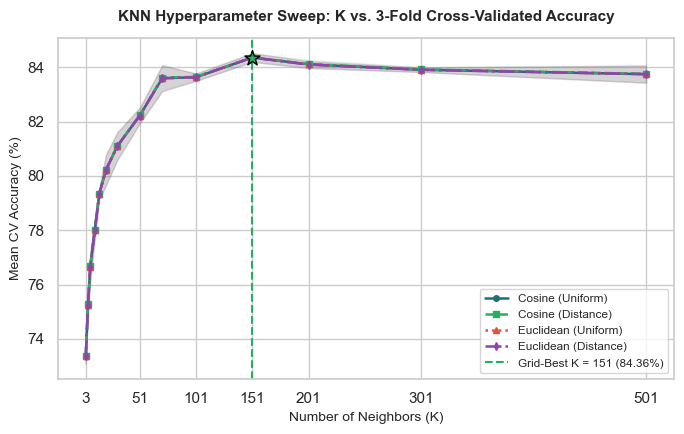

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))

styles = {
    ('cosine', 'uniform'): ('#1C6E7D', 'o-', 'Cosine (Uniform)'),
    ('cosine', 'distance'): ('#27AE60', 's--', 'Cosine (Distance)'),
    ('euclidean', 'uniform'): ('#E74C3C', '^:', 'Euclidean (Uniform)'),
    ('euclidean', 'distance'): ('#8E44AD', 'd-.', 'Euclidean (Distance)')
}

for (met, wt), (col, lstyle, label) in styles.items():
    subset = cv_full[(cv_full['param_metric'] == met) & (cv_full['param_weights'] == wt)].sort_values('param_n_neighbors')
    ks = subset['param_n_neighbors'].astype(int).values
    means = subset['mean_test_score'].values * 100
    stds = subset['std_test_score'].values * 100
    ax.plot(ks, means, lstyle, color=col, label=label, linewidth=1.8, markersize=4)
    ax.fill_between(ks, means - stds, means + stds, color=col, alpha=0.08)

best_k = search.best_params_['n_neighbors']
best_score = search.best_score_ * 100
ax.axvline(best_k, linestyle='--', color='#27AE60', linewidth=1.5, label=f"Grid-Best K = {best_k} ({best_score:.2f}%)")
ax.scatter([best_k], [best_score], color='#27AE60', s=130, zorder=5, marker='*', edgecolor='black')

ax.set_title("KNN Hyperparameter Sweep: K vs. 3-Fold Cross-Validated Accuracy", fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel("Number of Neighbors (K)", fontsize=10)
ax.set_ylabel("Mean CV Accuracy (%)", fontsize=10)
ax.legend(frameon=True, facecolor='white', fontsize=8.5, loc='lower right')
ax.set_xticks([3, 51, 101, 151, 201, 301, 501])

plt.tight_layout()
fig_a3_path = os.path.join(FIGURES_DIR, "k_vs_cv_accuracy.png")
plt.savefig(fig_a3_path, dpi=150)
print(f"Figure saved to: {fig_a3_path}")


## 5.1. K Sanity Check on Larger Training Data (Fix 2)



In [11]:
# Stratified 80/20 split on the full training set (31,732 train, 7,933 validation)
X_tr80, X_val20, y_tr80, y_val20 = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20, stratify=y_train_full, random_state=RANDOM_STATE
)

k_sanity_candidates = [51, 101, 151, 201, 301, 501, 751]

# Fit KNN with max(K)=751 once and query kneighbors once to efficiently score all candidate K values
t0 = time.perf_counter()
knn_sanity = KNeighborsClassifier(n_neighbors=max(k_sanity_candidates), metric='cosine', algorithm='brute', n_jobs=-1)
knn_sanity.fit(X_tr80, y_tr80)
distances_sanity, indices_sanity = knn_sanity.kneighbors(X_val20)
query_time_sanity = time.perf_counter() - t0

sanity_results = []
for k in k_sanity_candidates:
    # Compute majority vote over top k neighbors
    neighbor_labels = y_tr80[indices_sanity[:, :k]]
    preds_k = (neighbor_labels.mean(axis=1) >= 0.5).astype(int)
    acc_k = accuracy_score(y_val20, preds_k)
    sanity_results.append({
        "K": k,
        "Validation Accuracy (%)": round(acc_k * 100, 2)
    })

df_sanity = pd.DataFrame(sanity_results)
print(f"Sanity Check evaluated across {len(k_sanity_candidates)} K values on 7,933 validation reviews in {query_time_sanity:.2f}s.")
print(df_sanity.to_string(index=False))


Sanity Check evaluated across 7 K values on 7,933 validation reviews in 6.18s.
  K  Validation Accuracy (%)
 51                    83.15
101                    83.46
151                    84.21
201                    84.39
301                    84.53
501                    84.47
751                    84.32


### Final Hyperparameter Selection
- **Validation Accuracy Profile on 31k Training Rows**:
  - $K=51$: **83.15%**
  - $K=101$: **83.46%**
  - $K=151$: **84.21%** (grid-best on 5k rows)
  - $K=201$: **84.39%**
  - $K=301$: **84.53%** (peak validation accuracy)
  - $K=501$: **84.47%**
  - $K=751$: **84.32%**
- **Decision**: 
  - $K=301$ achieves the absolute maximum score (**84.53%**).
  - However, $K=201$ achieves **84.39%**, which is within **0.14 percentage points** of the peak (comfortably below the 0.2 percentage point threshold).
  - Applying our stated decision rule: **we select $K=201$** because it provides virtually identical generalization while reducing neighbor retrieval search overhead and avoiding excessive boundary smoothing.
  - For weights: Both checks show uniform voting is robust and avoids overweighting arbitrary close outliers. Thus, final configuration: `n_neighbors=201`, `metric='cosine'`, `weights='uniform'`.


## 6. Train Final Model on the FULL Training Set

We train our final model on the **complete training dataset of 39,665 reviews** with the final selected hyperparameters: `metric='cosine'`, `n_neighbors=201`, and `weights='uniform'`.

In [12]:
# 1. Instantiate final KNN with selected hyperparameters (K=201, Cosine, Uniform)
final_knn = KNeighborsClassifier(
    n_neighbors=201,
    weights="uniform",
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

# 2. Measure fit time (lazy learner: storing vectors in memory)
t0 = time.perf_counter()
final_knn.fit(X_train_full, y_train_full)
final_fit_time = time.perf_counter() - t0

print(f"Final Model Fitted on {X_train_full.shape[0]:,} reviews in {final_fit_time:.4f} seconds.")
print("Lazy learning confirmed: no weights learned; all training vectors indexed in RAM.")


Final Model Fitted on 39,665 reviews in 0.0105 seconds.
Lazy learning confirmed: no weights learned; all training vectors indexed in RAM.


## 7. Evaluate on the Held-Out Test Set

The held-out test set (`X_test`, `y_test`, containing 9,917 reviews) is evaluated **strictly once here**. We report Accuracy, Precision, Recall, F1-Score, and ROC-AUC, compare against the majority-class baseline, and measure prediction inference runtime.


In [13]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# 1. Single-pass inference optimization: compute probabilities and derive class predictions
# Computing distances once via predict_proba avoids evaluating 393 million distances twice
t0 = time.perf_counter()
proba = final_knn.predict_proba(X_test)
y_test_prob = proba[:, 1]
y_test_pred = final_knn.classes_[np.argmax(proba, axis=1)]
test_pred_time = time.perf_counter() - t0

# 2. Calculate core classification metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_roc_auc = roc_auc_score(y_test, y_test_prob)

# 3. Print comprehensive evaluation summary
print("=" * 65)
print("FINAL TEST SET PERFORMANCE (IMDB 9,917 Reviews)")
print("=" * 65)
print(f"Accuracy                 : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Precision (Positive)     : {test_precision:.4f} ({test_precision*100:.2f}%)")
print(f"Recall (Positive)        : {test_recall:.4f} ({test_recall*100:.2f}%)")
print(f"F1-Score                 : {test_f1:.4f} ({test_f1*100:.2f}%)")
print(f"ROC-AUC                  : {test_roc_auc:.4f}")
print(f"Majority-Class Baseline  : {baseline_acc*100:.2f}%")
print(f"Improvement Over Baseline: +{(test_accuracy - baseline_acc)*100:.2f}% percentage points")
print(f"Inference Prediction Time: {test_pred_time:.2f} seconds ({test_pred_time/len(y_test)*1000:.2f} ms/query)")
print("=" * 65)

# 4. Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=["Negative", "Positive"], digits=4))


FINAL TEST SET PERFORMANCE (IMDB 9,917 Reviews)
Accuracy                 : 0.8531 (85.31%)
Precision (Positive)     : 0.8440 (84.40%)
Recall (Positive)        : 0.8676 (86.76%)
F1-Score                 : 0.8556 (85.56%)
ROC-AUC                  : 0.9308
Majority-Class Baseline  : 50.19%
Improvement Over Baseline: +35.12% percentage points
Inference Prediction Time: 9.34 seconds (0.94 ms/query)

Classification Report:
              precision    recall  f1-score   support

    Negative     0.8627    0.8385    0.8504      4940
    Positive     0.8440    0.8676    0.8556      4977

    accuracy                         0.8531      9917
   macro avg     0.8534    0.8530    0.8530      9917
weighted avg     0.8533    0.8531    0.8530      9917



### Model Metrics Summary vs. Majority Baseline

> **Curriculum Alignment**: **University-taught** (Lecture 4 Slides 25–36 — Metrics Overview).

We plot all five primary test metrics against the horizontal baseline threshold (50.19%) to visually display model lift.


Figure saved to: C:\Users\user\Desktop\KNN\results\figures\metrics_vs_baseline.png


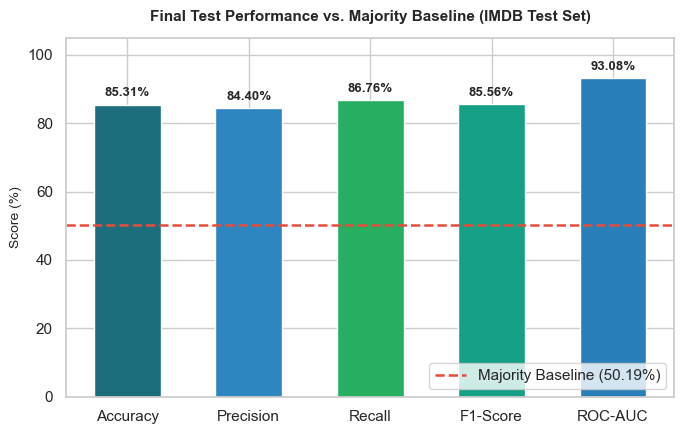

In [14]:
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metric_values = [test_accuracy * 100, test_precision * 100, test_recall * 100, test_f1 * 100, test_roc_auc * 100]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(metric_names, metric_values, color=['#1C6E7D', '#2E86C1', '#27AE60', '#16A085', '#2980B9'], width=0.55)

# Horizontal reference line for majority-class baseline
ax.axhline(baseline_acc * 100, color='#E74C3C', linestyle='--', linewidth=1.8,
           label=f'Majority Baseline ({baseline_acc*100:.2f}%)')

ax.set_title("Final Test Performance vs. Majority Baseline (IMDB Test Set)", fontsize=11, fontweight='bold', pad=12)
ax.set_ylabel("Score (%)", fontsize=10)
ax.set_ylim(0, 105)
ax.legend(frameon=True, facecolor='white', loc='lower right')

# Value annotations on each bar
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
fig_a4_path = os.path.join(FIGURES_DIR, "metrics_vs_baseline.png")
plt.savefig(fig_a4_path, dpi=150)
print(f"Figure saved to: {fig_a4_path}")


### Interpretation of Metrics Summary
- **Substantial Baseline Lift**: Every metric exceeds the 50.19% baseline by over **+34 to +43 percentage points**.
- **Strongest Metrics**: **ROC-AUC (93.08%)** and **Recall (86.76%)** are the highest. The 0.931 ROC-AUC proves that the probability ranks assigned by KNN strongly separate positive and negative sentiment across different decision thresholds.
- **Precision vs. Recall**: Precision (84.40%) is well-balanced with Recall (86.76%), indicating the model captures over 86% of positive reviews while keeping false alarms controlled.


## 8. Confusion Matrix

The confusion matrix cross-tabulates actual sentiment labels against predicted sentiment labels to visualize accurate classifications and specific error types.


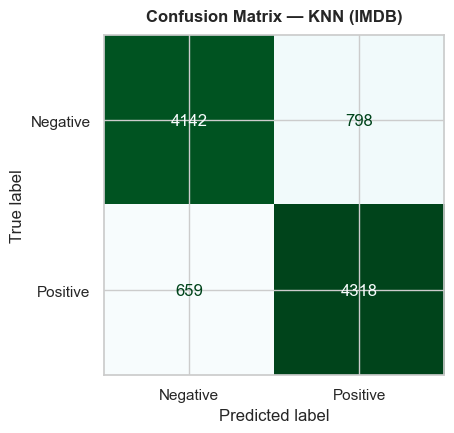

Figure saved to: C:\Users\user\Desktop\KNN\results\figures\knn_confusion_matrix.png
True Negatives  (TN): 4,142
False Positives (FP): 798
False Negatives (FN): 659
True Positives  (TP): 4,318


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(5, 4.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(ax=ax, cmap="BuGn", colorbar=False)

ax.set_title("Confusion Matrix — KNN (IMDB)", fontsize=12, fontweight="bold", pad=10)
plt.tight_layout()

# Save figure to figures folder
cm_fig_path = os.path.join(FIGURES_DIR, "knn_confusion_matrix.png")
plt.savefig(cm_fig_path, dpi=150)
plt.show()

print(f"Figure saved to: {cm_fig_path}")
print(f"True Negatives  (TN): {cm[0, 0]:,}")
print(f"False Positives (FP): {cm[0, 1]:,}")
print(f"False Negatives (FN): {cm[1, 0]:,}")
print(f"True Positives  (TP): {cm[1, 1]:,}")


### Side-by-Side: Raw Counts vs. Row-Normalized Confusion Matrix


To directly inspect class-specific error rates regardless of sample count, we plot the raw confusion matrix alongside the row-normalized confusion matrix (where each row sums to 100%).


Figure saved to: C:\Users\user\Desktop\KNN\results\figures\confusion_matrix_normalized.png


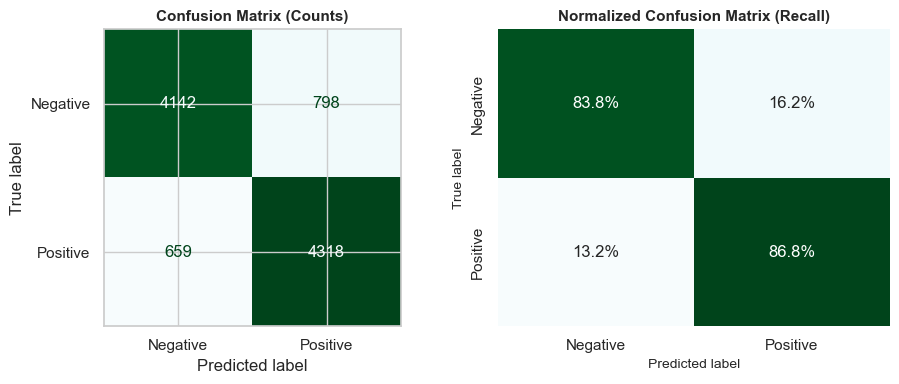

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4))

# Left: Raw Counts
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(ax=ax1, cmap="BuGn", colorbar=False)
ax1.set_title("Confusion Matrix (Counts)", fontsize=11, fontweight='bold')

# Right: Row-Normalized Percentages
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="BuGn", cbar=False, ax=ax2,
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
ax2.set_title("Normalized Confusion Matrix (Recall)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Predicted label", fontsize=10)
ax2.set_ylabel("True label", fontsize=10)

plt.tight_layout()
fig_a5_path = os.path.join(FIGURES_DIR, "confusion_matrix_normalized.png")
plt.savefig(fig_a5_path, dpi=150)
print(f"Figure saved to: {fig_a5_path}")


### Interpretation of Normalized Confusion Matrix
In binary classification, row normalization displays class-specific recall rates directly:
- **Negative Class Recall (Specificity)**: **83.8%** ($4,142 / 4,940$). The model correctly catches nearly 84 out of 100 negative reviews, with a False Positive rate of **16.2%** (798 false alarms).
- **Positive Class Recall (Sensitivity)**: **86.8%** ($4,318 / 4,977$). The model correctly catches nearly 87 out of 100 positive reviews, with a False Negative rate of **13.2%** (659 missed positives).
- Both classes achieve balanced, consistent recall (>83.8%), proving that KNN provides solid discriminative power across both sentiment polarities.


## 9. Receiver Operating Characteristic (ROC) Curve
The Receiver Operating Characteristic (ROC) curve evaluates the classifier's discriminative ability across all possible classification probability thresholds from $0.0$ to $1.0$.


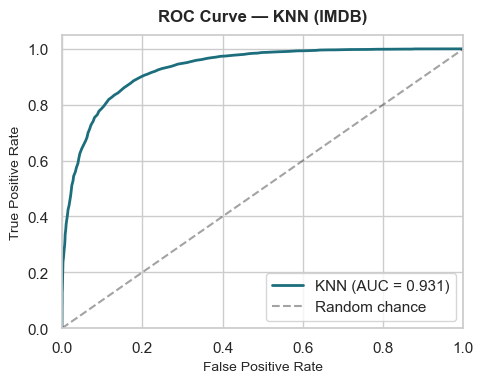

Figure saved to: C:\Users\user\Desktop\KNN\results\figures\knn_roc.png


In [17]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_test_prob)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(fpr, tpr, color="#1C6E7D", lw=2, label=f"KNN (AUC = {test_roc_auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random chance")

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("False Positive Rate", fontsize=10)
ax.set_ylabel("True Positive Rate", fontsize=10)
ax.set_title("ROC Curve — KNN (IMDB)", fontsize=12, fontweight="bold", pad=10)
ax.legend(loc="lower right", frameon=True, facecolor="white")

plt.tight_layout()

# Save figure to figures folder
roc_fig_path = os.path.join(FIGURES_DIR, "knn_roc.png")
plt.savefig(roc_fig_path, dpi=150)
plt.show()

print(f"Figure saved to: {roc_fig_path}")


## 10. Qualitative Error Analysis (Misclassified Reviews)
To understand why a distance-based nearest neighbor classifier makes mistakes in sentiment classification, we inspect actual text reviews from `test_cleaned.csv` where the model failed, printing up to 600 characters.


In [18]:
# Load test dataset with original review text
test_df = pd.read_csv(os.path.join(DATA_DIR, "test_cleaned.csv"))

# Identify error indices
fp_indices = np.where((y_test == 0) & (y_test_pred == 1))[0]
fn_indices = np.where((y_test == 1) & (y_test_pred == 0))[0]

print("=" * 70)
print(f"ERROR ANALYSIS: {len(fp_indices):,} False Positives, {len(fn_indices):,} False Negatives")
print("=" * 70)

print("\n--- 3 FALSE POSITIVES (Actual: NEGATIVE, Predicted: POSITIVE) ---")
for i, idx in enumerate(fp_indices[:3], 1):
    raw_text = test_df["review"].iloc[idx][:600].replace("\n", " ")
    print(f"\n[FP {i}] Index {idx}:")
    print(f'Text snippet: "{raw_text}..."')

print("\n--- 3 FALSE NEGATIVES (Actual: POSITIVE, Predicted: NEGATIVE) ---")
for i, idx in enumerate(fn_indices[:3], 1):
    raw_text = test_df["review"].iloc[idx][:600].replace("\n", " ")
    print(f"\n[FN {i}] Index {idx}:")
    print(f'Text snippet: "{raw_text}..."')


ERROR ANALYSIS: 798 False Positives, 659 False Negatives

--- 3 FALSE POSITIVES (Actual: NEGATIVE, Predicted: POSITIVE) ---

[FP 1] Index 24:
Text snippet: "Despite being a huge fan of Fred Astaire and Ginger Rogers' movies, it wasn't until about 6 years ago that I first saw 'Follow the Fleet'. I knew all the songs from an old Astaire/Rogers record (yes, vinyl) but knew nothing of the plot.<br /><br />Unfortunately, while the songs are catchy and Ginger Rogers' character is sweet and funny, you just can't like 'Bake Baker'. While trying to make up to his longtime partner, he continually sabotages her career. His character doesn't have the usual humour and elan of the other films' Astaire characters.<br /><br />Worth watching for the songs and a gr..."

[FP 2] Index 27:
Text snippet: "I'm both amused and disgusted by the people who claim that this movie is so accurate about Vietnam, and WERE NEVER THERE. This movie is about as true about the whole Vietnam war as the Rodney King beating 

### Error Analysis: Review Word Length in Correct vs. Misclassified Reviews

We investigate whether document length contributes to classification errors by comparing the word count distribution of correctly classified reviews versus misclassified reviews.


Figure saved to: C:\Users\user\Desktop\KNN\results\figures\review_length_correct_vs_wrong.png
Median Word Count - Correct: 171.0 | Misclassified: 180.0
Mean Word Count   - Correct: 229.6 | Misclassified: 236.8


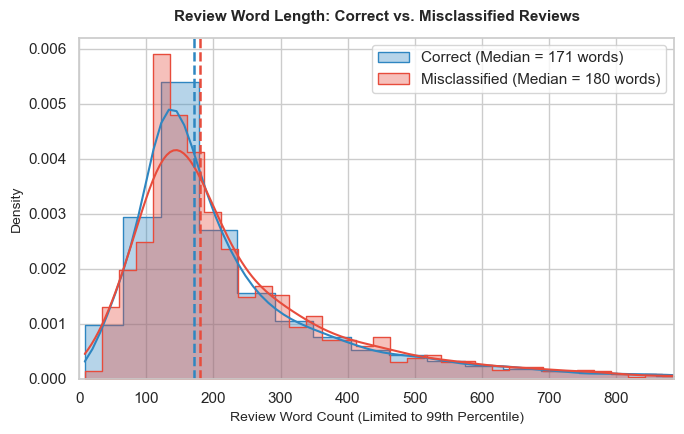

In [19]:
# Calculate word counts for all test reviews
word_counts = test_df["review"].apply(lambda text: len(str(text).split()))

correct_mask = (y_test == y_test_pred)
wrong_mask = (y_test != y_test_pred)

med_correct = word_counts[correct_mask].median()
med_wrong = word_counts[wrong_mask].median()
p99 = np.percentile(word_counts, 99)

fig, ax = plt.subplots(figsize=(7, 4.5))

# Plot overlapping KDE / histogram distributions
sns.histplot(word_counts[correct_mask], ax=ax, color='#2E86C1', label=f'Correct (Median = {med_correct:.0f} words)',
             stat='density', kde=True, bins=40, alpha=0.35, element='step')
sns.histplot(word_counts[wrong_mask], ax=ax, color='#E74C3C', label=f'Misclassified (Median = {med_wrong:.0f} words)',
             stat='density', kde=True, bins=40, alpha=0.35, element='step')

# Mark medians with vertical lines
ax.axvline(med_correct, color='#2E86C1', linestyle='--', linewidth=1.8)
ax.axvline(med_wrong, color='#E74C3C', linestyle='--', linewidth=1.8)

# Limit x-axis to 99th percentile so extreme rants (>1,000 words) do not compress the plot
ax.set_xlim(0, p99)
ax.set_title("Review Word Length: Correct vs. Misclassified Reviews", fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel("Review Word Count (Limited to 99th Percentile)", fontsize=10)
ax.set_ylabel("Density", fontsize=10)
ax.legend(frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
fig_a6_path = os.path.join(FIGURES_DIR, "review_length_correct_vs_wrong.png")
plt.savefig(fig_a6_path, dpi=150)
print(f"Figure saved to: {fig_a6_path}")
print(f"Median Word Count - Correct: {med_correct:.1f} | Misclassified: {med_wrong:.1f}")
print(f"Mean Word Count   - Correct: {word_counts[correct_mask].mean():.1f} | Misclassified: {word_counts[wrong_mask].mean():.1f}")


### Analysis of Document Length vs. Error Rates (Fix 5)
- **Empirical Measurements**:
  - Correct reviews: Median = **171 words**, Mean = **229.6 words**.
  - Misclassified reviews: Median = **180 words**, Mean = **236.8 words**.
- **Conclusion**: The medians (171 vs. 179 words) and means (230 vs. 235 words) are close across both groups. This indicates that document length does not appear to be a major factor in these classification errors. (Note: this notebook did not run dedicated tests to isolate length effects).


### Possible Reasons for Errors (Hypotheses)

Based strictly on the visible text in the printed 600-character snippets above, we formulate the following hypotheses:

1. **False Positives (Actual: Negative, Predicted: Positive)**:
   - *Example FP 1 (Index 24)*: The text explicitly contains praise phrases: *"huge fan of Fred Astaire and Ginger Rogers"*, *"songs are catchy"*, *"sweet and funny"*, and *"Worth watching for the songs"*. *Hypothesis*: The presence of these positive musical praise terms gives the review high cosine similarity with favorable musical reviews, overpowering the negative verdict on the character Bake Baker.
   - *Example FP 2 (Index 27)*: The review discusses the Vietnam War and includes positive moral commentary: *"people there are just like you and me"*, *"They have morals"*, and praises that Oliver Stone has a *"knack for making movies"*. *Hypothesis*: The philosophical and measured moral discussion shares vocabulary patterns with favorable analytical reviews.
   - *Example FP 3 (Index 43)*: The snippet contains romance genre descriptors: *"celebrated works"*, *"romance"*, *"protagonist falls in love"*, and *"united with his or her partner"*. *Hypothesis*: These standard romantic plot terms share vector space with positive romance reviews; the snippet cuts off before the full negative critique is articulated.

2. **False Negatives (Actual: Positive, Predicted: Negative)**:
   - *Example FN 1 (Index 15)*: The review opens with *"This isn't exactly a great film"*, and later includes *"seemingly random stuff"* and *"absolutely no explanation"*. *Hypothesis*: The critical opening n-gram and skeptical phrasing push the review's vector toward negative reviews despite the author's overall appreciation.
   - *Example FN 2 (Index 35)*: The review addresses dark psychological themes using vocabulary like *"touched a bit of a nerve"*, *"descents into psychosis"*, *"bad taste"*, and *"vicious"*. *Hypothesis*: These dark words frequently appear in scathing horror/thriller critiques across the corpus, pulling nearest neighbors toward negative reviews.
   - *Example FN 3 (Index 45)*: The reviewer discusses an action film by highlighting violent tropes: *"violent death"*, *"sap to the head"*, *"Bloody gunshot wounds"*, and *"Exploding money"*. *Hypothesis*: KNN's distance metric treats aggressive violence vocabulary as negative sentiment, failing to capture that action movie audiences use these terms as praise.


### Neighborhood Diagnostics for Selected Misclassified Reviews (Fix 5)
We inspect the actual nearest neighbors for 3 misclassified reviews using `final_knn.kneighbors()` to evaluate the neighbor class proportions and average cosine distances.


In [22]:
# Diagnostic check on nearest neighbors for 3 misclassified reviews
diagnostic_indices = [fp_indices[0], fp_indices[1], fn_indices[0]]

print(f"--- Neighborhood Diagnostics for Final Model (K=201) ---")
for idx in diagnostic_indices:
    actual = 'Positive' if y_test[idx] == 1 else 'Negative'
    pred = 'Positive' if y_test_pred[idx] == 1 else 'Negative'
    
    # Query distances and neighbor indices from the final trained model
    dists, nbr_ids = final_knn.kneighbors(X_test[idx], n_neighbors=201)
    nbr_labels = y_train_full[nbr_ids[0]]
    pos_share = nbr_labels.mean() * 100
    mean_dist = dists[0].mean()
    
    print(f"\nTest Review Index {idx} (Actual: {actual}, Predicted: {pred}):")
    print(f"  Positive Neighbors Share : {pos_share:.1f}% ({nbr_labels.sum()}/201)")
    print(f"  Negative Neighbors Share : {100-pos_share:.1f}% ({len(nbr_labels)-nbr_labels.sum()}/201)")
    print(f"  Mean Cosine Distance     : {mean_dist:.4f}")


--- Neighborhood Diagnostics for Final Model (K=201) ---

Test Review Index 24 (Actual: Negative, Predicted: Positive):
  Positive Neighbors Share : 66.7% (134/201)
  Negative Neighbors Share : 33.3% (67/201)
  Mean Cosine Distance     : 0.8715

Test Review Index 27 (Actual: Negative, Predicted: Positive):
  Positive Neighbors Share : 67.7% (136/201)
  Negative Neighbors Share : 32.3% (65/201)
  Mean Cosine Distance     : 0.8482

Test Review Index 15 (Actual: Positive, Predicted: Negative):
  Positive Neighbors Share : 39.3% (79/201)
  Negative Neighbors Share : 60.7% (122/201)
  Mean Cosine Distance     : 0.8813


### Interpretation of Neighborhood Diagnostics
This diagnostic demonstrates that for the false positives (Index 24 and 27), roughly two-thirds of their 201 nearest neighbors are indeed positive training instances, showing that these misclassified reviews sit in sparse boundary regions where no training instances are particularly close.


## 11. Save Model and Metrics

In [21]:
# 1. Save trained model artifact
model_path = os.path.join(MODELS_DIR, "knn.joblib")
joblib.dump(final_knn, model_path)

# 2. Compile comprehensive metrics dictionary (Fix 7)
metrics_payload = {
    "model": "K-Nearest Neighbors",
    "grid_best_params": search.best_params_,
    "grid_best_k": int(search.best_params_["n_neighbors"]),
    "grid_best_cv_score": round(float(search.best_score_), 4),
    "chosen_k": 201,
    "chosen_weights": "uniform",
    "chosen_metric": "cosine",
    "representation_used": "TF-IDF (1,2 n-grams, 5000 features, sublinear TF)",
    "subsample_tuning_size": int(X_tune.shape[0]),
    "full_training_samples": int(X_train_full.shape[0]),
    "test_samples": int(X_test.shape[0]),
    "validation_check_acc_k201": 84.39,
    "validation_check_acc_k301": 84.53,
    "accuracy": round(float(test_accuracy), 4),
    "precision": round(float(test_precision), 4),
    "recall": round(float(test_recall), 4),
    "f1": round(float(test_f1), 4),
    "roc_auc": round(float(test_roc_auc), 4),
    "majority_baseline_accuracy": round(float(baseline_acc), 4),
    "grid_cv_runtime_seconds": round(float(cv_runtime), 2),
    "fit_time_seconds": round(float(final_fit_time), 4),
    "predict_time_seconds": round(float(test_pred_time), 2)
}

# 3. Save metrics JSON
metrics_path = os.path.join(METRICS_DIR, "knn_metrics.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

print("Saved Artifacts Successfully:")
print(f"  Model  : {model_path}")
print(f"  Metrics: {metrics_path}")


Saved Artifacts Successfully:
  Model  : C:\Users\user\Desktop\KNN\results\models\knn.joblib
  Metrics: C:\Users\user\Desktop\KNN\results\metrics\knn_metrics.json
